# Netflix Content Intelligence and Recommendation System
## Auspify Technologies — Data Science Internship Tasks 1–6

**Business problem**  
How can a streaming platform use catalogue data to understand its content library, help users discover related titles, examine historical catalogue patterns, and support evidence-based catalogue planning?

**General objective**  
To transform Netflix catalogue metadata into reliable analytical insights, content-based recommendations, historical trend analysis, a classification model, and an interactive business insights dashboard.

### Scope and interpretation
This project uses the supplied `Dataset.csv` file (8,790 records and 10 columns). It contains catalogue metadata, not individual viewing histories, ratings submitted by users, watch time, or customer outcomes. Therefore:
- recommendations are **content-based**, not personalized from individual viewing histories;
- classification predicts whether a title is a Movie or TV Show using selected metadata while excluding `duration` to reduce target leakage;
- trend analysis uses `date_added` to count titles added to the dataset by year; forecasts are exploratory and should not be treated as Netflix acquisition plans;
- business recommendations are hypotheses to investigate, not causal claims.

### Tasks covered
1. Data cleaning and preprocessing
2. Exploratory data analysis (EDA)
3. Content-based recommendation system
4. Historical content trend analysis and forecasting
5. Machine learning classification
6. Business insights dashboard and recommendations

### Setup
Install any missing packages in your environment if needed: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, and `plotly`. The notebook does not require a paid API or external service.

## 0. Imports and load the supplied dataset

The loader checks common locations so the notebook works when kept beside `Dataset.csv`, in the same folder as this notebook, or when the CSV is in `/mnt/data` in this environment. If needed, edit `DATA_PATH` below.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

candidate_paths = [
    Path("Dataset.csv"),
    Path("../Dataset.csv"),
    Path("/mnt/data/Dataset.csv"),
    Path("data/raw/Dataset.csv"),
    Path("../data/raw/Dataset.csv"),
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset.csv was not found. Place it beside the notebook or update DATA_PATH."
    )

raw_df = pd.read_csv(DATA_PATH)
df = raw_df.copy()
print(f"Loaded: {DATA_PATH.resolve()}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Loaded: /mnt/data/Dataset.csv
Shape: 8,790 rows × 10 columns


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


# Task 1 — Data Cleaning and Preprocessing

## 1.1 Initial data audit

We first inspect the schema, data types, missing values recognised by Pandas, duplicate rows, duplicate IDs, and values that use text markers such as `Not Given` to represent missing information.

In [2]:
print("Dataset shape:", df.shape)
print("\nColumn types and non-null counts:")
df.info()

print("\nPandas-recognized missing values:")
display(df.isna().sum().rename("missing_count").to_frame())

print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Duplicate show_id values:", int(df["show_id"].duplicated().sum()) if "show_id" in df else "show_id not found")

marker_counts = {}
for col in df.select_dtypes(include="object").columns:
    count = df[col].astype("string").str.strip().str.lower().isin(["not given", "unknown", "n/a", "na", "none", "null", ""]).sum()
    if count:
        marker_counts[col] = int(count)
print("Text markers / blank-like values by column:", marker_counts)
display(df.describe(include="all").T)

Dataset shape: (8790, 10)

Column types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB

Pandas-recognized missing values:


,missing_count
show_id,0
type,0
title,0
director,0
country,0
date_added,0
release_year,0
rating,0
duration,0
listed_in,0


Exact duplicate rows: 0
Duplicate show_id values: 0
Text markers / blank-like values by column: {'title': 1, 'director': 2588, 'country': 287}


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8790,8790,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8790,2,Movie,6126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8790,8787,9-Feb,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,8790,4528,Not Given,2588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,8790,86,United States,3240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8790,1713,1/1/2020,110,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8790.0,NaN,NaN,NaN,2014.183163,8.825466,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8790,14,TV-MA,3205,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8790,220,1 Season,1791,NaN,NaN,NaN,NaN,NaN,NaN,NaN
listed_in,8790,513,"Dramas, International Movies",362,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1.2 Clean values using documented decisions

Cleaning decisions:
- trim leading/trailing spaces from text columns;
- convert known missing markers to actual missing values;
- parse `date_added` as a datetime, allowing invalid dates to become missing for review;
- enforce numeric `release_year` where possible;
- remove exact duplicate rows, if any, and keep the first record for duplicated `show_id` values, if any;
- do **not** delete a title simply because director or country information is unavailable.

The original `raw_df` remains unchanged for traceability.

In [3]:
clean_df = raw_df.copy()

# Trim text columns first.
text_cols = clean_df.select_dtypes(include="object").columns.tolist()
for col in text_cols:
    clean_df[col] = clean_df[col].astype("string").str.strip()

# Standardize known missing-value placeholders (case-insensitive).
missing_tokens = {"not given", "unknown", "n/a", "na", "none", "null", ""}
for col in text_cols:
    normalized = clean_df[col].astype("string").str.strip().str.lower()
    clean_df.loc[normalized.isin(missing_tokens), col] = pd.NA

# Convert data types.
if "date_added" in clean_df:
    clean_df["date_added"] = pd.to_datetime(clean_df["date_added"], errors="coerce")
if "release_year" in clean_df:
    clean_df["release_year"] = pd.to_numeric(clean_df["release_year"], errors="coerce").astype("Int64")

# Remove exact duplicates and duplicate identifiers, if present.
rows_before = len(clean_df)
clean_df = clean_df.drop_duplicates()
exact_duplicates_removed = rows_before - len(clean_df)
ids_removed = 0
if "show_id" in clean_df.columns:
    rows_before_ids = len(clean_df)
    clean_df = clean_df.drop_duplicates(subset=["show_id"], keep="first")
    ids_removed = rows_before_ids - len(clean_df)

print(f"Exact duplicate rows removed: {exact_duplicates_removed}")
print(f"Rows removed due to duplicate show_id: {ids_removed}")
print("Cleaned shape:", clean_df.shape)
print("\nMissing values after standardization:")
display(clean_df.isna().sum().rename("missing_count").to_frame())
print("\nUpdated data types:")
clean_df.info()

Exact duplicate rows removed: 0
Rows removed due to duplicate show_id: 0
Cleaned shape: (8790, 10)

Missing values after standardization:


,missing_count
show_id,0
type,0
title,1
director,2588
country,287
date_added,0
release_year,0
rating,0
duration,0
listed_in,0



Updated data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8790 non-null   string        
 1   type          8790 non-null   string        
 2   title         8789 non-null   string        
 3   director      6202 non-null   string        
 4   country       8503 non-null   string        
 5   date_added    8790 non-null   datetime64[ns]
 6   release_year  8790 non-null   Int64         
 7   rating        8790 non-null   string        
 8   duration      8790 non-null   string        
 9   listed_in     8790 non-null   string        
dtypes: Int64(1), datetime64[ns](1), string(8)
memory usage: 695.4 KB


## 1.3 Validate and create useful date features

We check category values and numeric ranges, then extract `date_added_year` and `date_added_month` from the parsed date. These features support the time-trend analysis in Task 4. We keep the original `date_added` date as well.

In [4]:
if "type" in clean_df:
    print("Content types:")
    display(clean_df["type"].value_counts(dropna=False).to_frame("count"))
if "release_year" in clean_df:
    print("Release year range:", clean_df["release_year"].min(), "to", clean_df["release_year"].max())
if "date_added" in clean_df:
    print("Date-added range:", clean_df["date_added"].min(), "to", clean_df["date_added"].max())
    clean_df["date_added_year"] = clean_df["date_added"].dt.year.astype("Int64")
    clean_df["date_added_month"] = clean_df["date_added"].dt.month.astype("Int64")

# Save cleaned data while preserving null values as empty CSV fields.
output_dir = Path("data/processed")
if not output_dir.exists():
    output_dir = Path("processed")
output_dir.mkdir(parents=True, exist_ok=True)
clean_csv_path = output_dir / "netflix_titles_cleaned.csv"
clean_df.to_csv(clean_csv_path, index=False)
print(f"Cleaned dataset saved to: {clean_csv_path.resolve()}")

Content types:


,count
type,
Movie,6126
TV Show,2664


Release year range: 1925 to 2021
Date-added range: 2008-01-01 00:00:00 to 2021-09-25 00:00:00


Cleaned dataset saved to: /mnt/data/processed/netflix_titles_cleaned.csv


### Task 1 conclusion

The dataset has been standardized without discarding titles merely because descriptive fields are unavailable. Missingness is now represented consistently as null values, `date_added` is a datetime column, and date-derived fields are available for time-based analysis. The saved CSV can be reused by the remaining tasks.

# Task 2 — Exploratory Data Analysis (EDA)

We examine the structure of the catalogue by type, release year, country, genre/category, and content rating. Counts are descriptive of this supplied dataset; they do not necessarily represent the full current Netflix catalogue.

Rows and columns: (8790, 12)
Movie / TV Show split:


,count,percent
type,,
Movie,6126,69.69
TV Show,2664,30.31


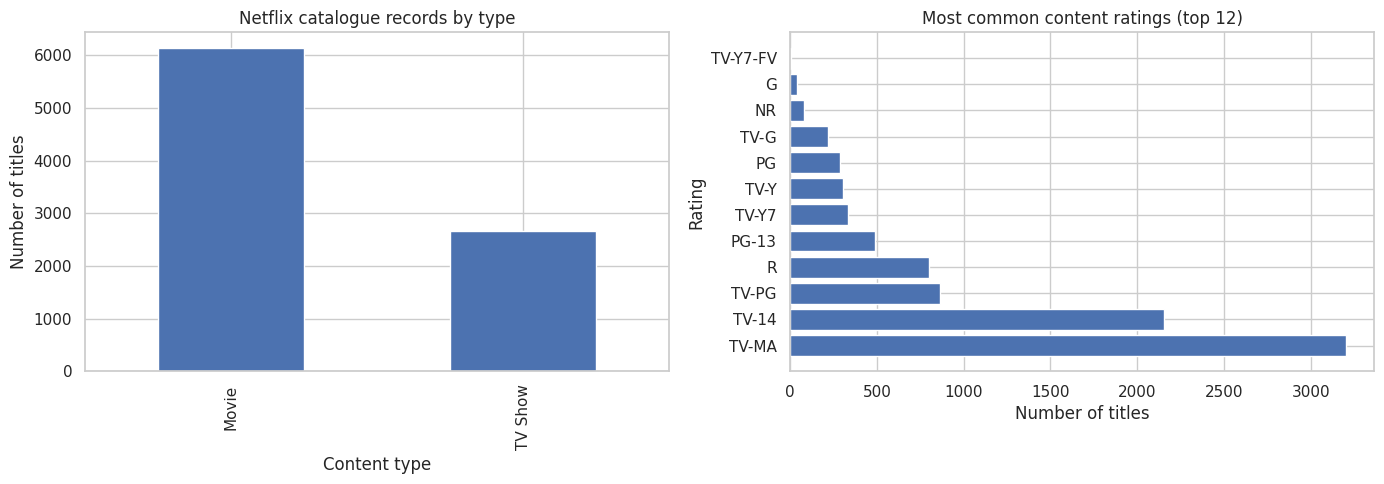

In [5]:
eda_df = clean_df.copy()
print("Rows and columns:", eda_df.shape)
print("Movie / TV Show split:")
type_counts = eda_df["type"].value_counts(dropna=False)
display(pd.DataFrame({"count": type_counts, "percent": (type_counts / len(eda_df) * 100).round(2)}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
type_counts.plot(kind="bar", ax=axes[0])
axes[0].set_title("Netflix catalogue records by type")
axes[0].set_xlabel("Content type")
axes[0].set_ylabel("Number of titles")

if "rating" in eda_df:
    rating_counts = eda_df["rating"].value_counts().head(12)
    axes[1].barh(rating_counts.index, rating_counts.values)
    axes[1].set_title("Most common content ratings (top 12)")
    axes[1].set_xlabel("Number of titles")
    axes[1].set_ylabel("Rating")
plt.tight_layout()
plt.show()

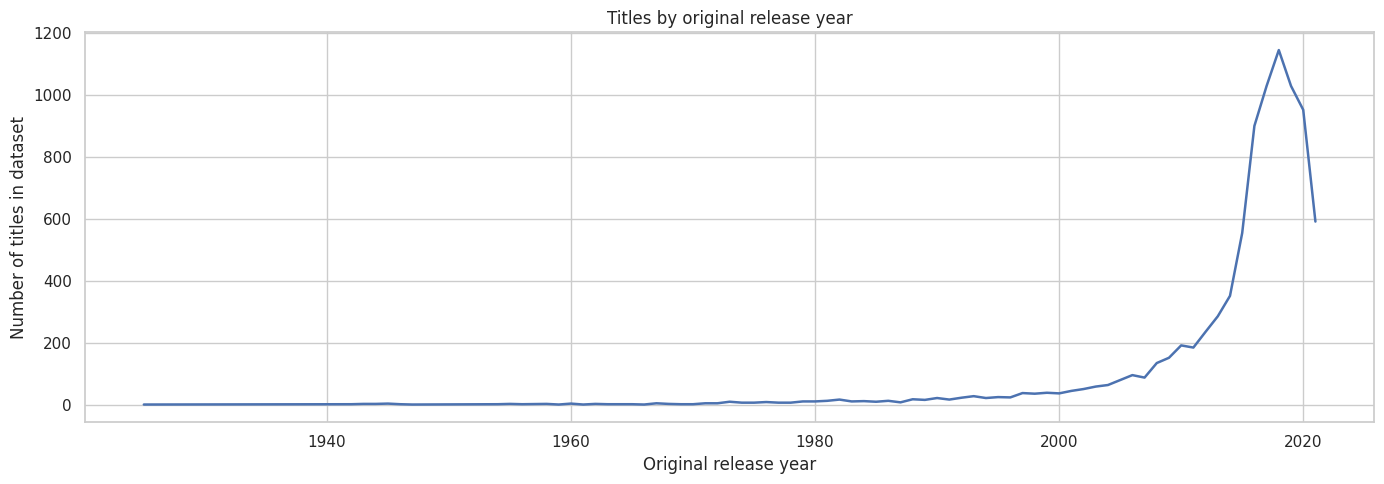

,title_country_mentions
country,
United States,3240
India,1057
United Kingdom,638
Pakistan,421
Canada,271
Japan,259
South Korea,214
France,213
Spain,182


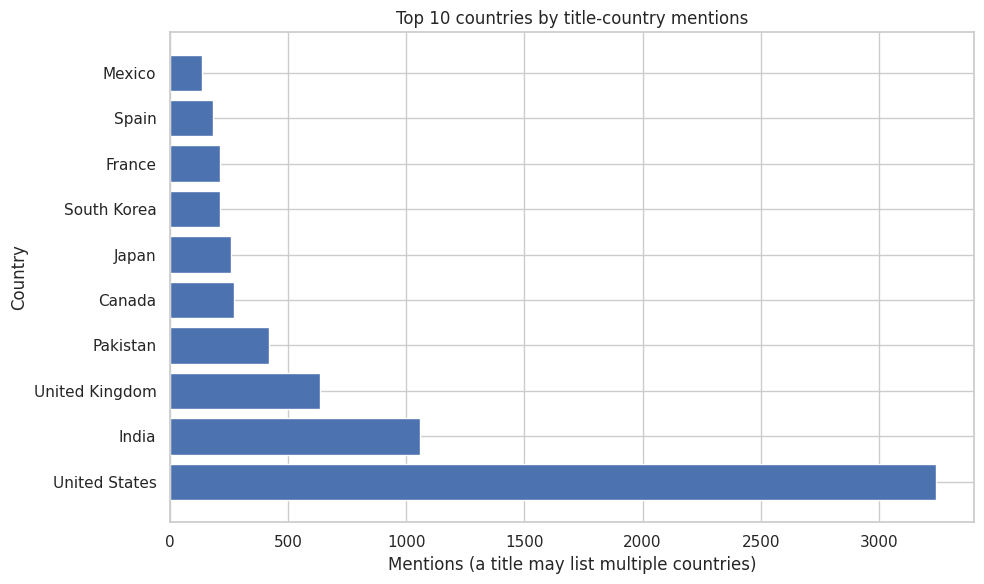

In [6]:
# Release-year distribution (counts of titles by original release year)
release_counts = eda_df["release_year"].dropna().astype(int).value_counts().sort_index()
plt.figure(figsize=(14, 5))
plt.plot(release_counts.index, release_counts.values, linewidth=1.8)
plt.title("Titles by original release year")
plt.xlabel("Original release year")
plt.ylabel("Number of titles in dataset")
plt.tight_layout()
plt.show()

# Top countries: country strings can contain multiple comma-separated countries,
# so split them and count each country mention separately.
country_mentions = (eda_df["country"].dropna().str.split(", ").explode().str.strip())
top_countries = country_mentions.value_counts().head(10)
display(top_countries.rename("title_country_mentions").to_frame())
plt.figure(figsize=(10, 6))
plt.barh(top_countries.index, top_countries.values)
plt.title("Top 10 countries by title-country mentions")
plt.xlabel("Mentions (a title may list multiple countries)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

,title_category_mentions
listed_in,
International Movies,2752
Dramas,2426
Comedies,1674
International TV Shows,1349
Documentaries,869
Action & Adventure,859
TV Dramas,762
Independent Movies,756
Children & Family Movies,641


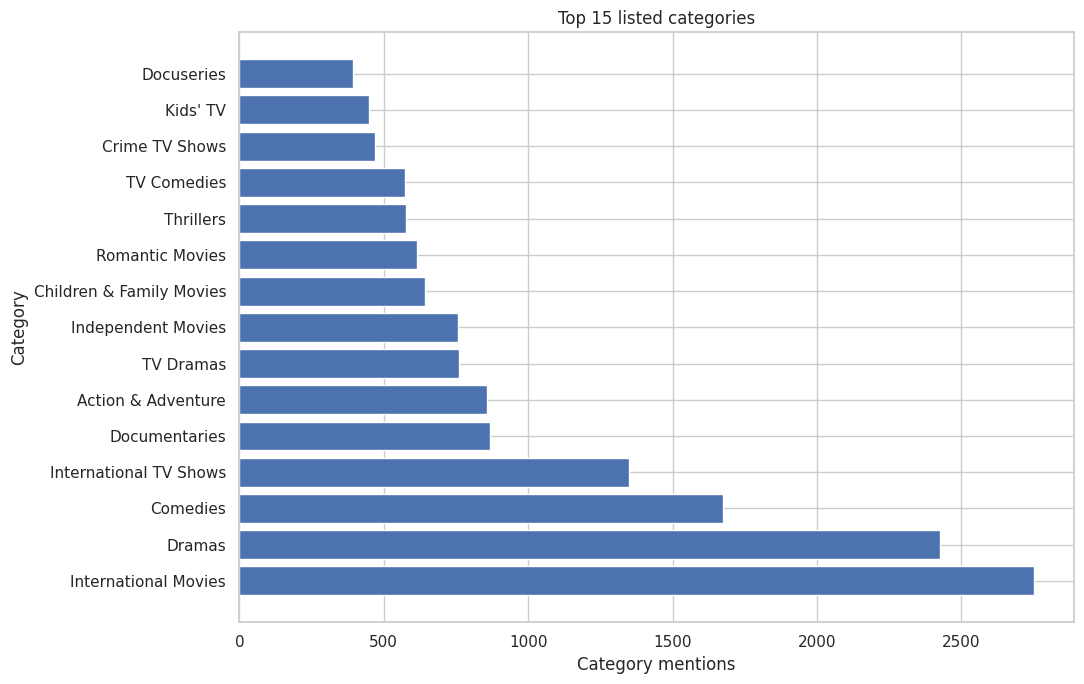

Median release year: 2017.0
Titles missing director: 2588
Titles missing country: 287


In [7]:
# Top listed categories / genres; one title can have multiple categories.
genre_mentions = eda_df["listed_in"].dropna().str.split(", ").explode().str.strip()
top_genres = genre_mentions.value_counts().head(15)
display(top_genres.rename("title_category_mentions").to_frame())
plt.figure(figsize=(11, 7))
plt.barh(top_genres.index, top_genres.values)
plt.title("Top 15 listed categories")
plt.xlabel("Category mentions")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

# Simple summary statistics
print("Median release year:", eda_df["release_year"].median())
print("Titles missing director:", int(eda_df["director"].isna().sum()))
print("Titles missing country:", int(eda_df["country"].isna().sum()))

## Task 2 — Interpretation guide

When writing your final EDA summary, use the charts and outputs above to report:
- whether movies or TV shows make up the larger share of this dataset;
- which countries and listed categories appear most often;
- how the distribution of original release years changes over time;
- which content ratings are most common;
- data limitations, including missing country/director fields and multi-valued country/category columns.

Avoid interpreting a large number of titles from a country or genre as proof of audience demand. This dataset contains no viewing or engagement metrics.

# Task 3 — Content-Based Recommendation System

The provided file has no description column or user viewing history. We will therefore create a baseline content-based recommender using available metadata: `listed_in`, `director`, `country`, `rating`, and `type`. TF-IDF converts text into numeric vectors and cosine similarity ranks titles with similar metadata.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

rec_df = clean_df.reset_index(drop=True).copy()
recommendation_fields = [c for c in ["listed_in", "director", "country", "rating", "type"] if c in rec_df.columns]

# Missing fields become empty strings in the recommendation text.
def combine_metadata(row):
    parts = []
    for field in recommendation_fields:
        value = row[field]
        if pd.notna(value):
            parts.append(str(value).replace(",", " "))
    return " ".join(parts)

rec_df["metadata_text"] = rec_df.apply(combine_metadata, axis=1)
vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
tfidf_matrix = vectorizer.fit_transform(rec_df["metadata_text"])
similarity_matrix = cosine_similarity(tfidf_matrix, dense_output=False)
print("Titles indexed:", len(rec_df))
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Metadata fields used:", recommendation_fields)

Titles indexed: 8790
TF-IDF matrix shape: (8790, 20857)
Metadata fields used: ['listed_in', 'director', 'country', 'rating', 'type']


In [9]:
def recommend_titles(title, n=5):
    """Return titles with the most similar available catalogue metadata."""
    matches = rec_df.index[rec_df["title"].astype(str).str.casefold() == str(title).casefold()].tolist()
    if not matches:
        # Helpful fallback: partial title match.
        matches = rec_df.index[rec_df["title"].astype(str).str.contains(str(title), case=False, na=False, regex=False)].tolist()
    if not matches:
        available = rec_df["title"].dropna().head(10).tolist()
        raise ValueError(f"Title not found. Example available titles: {available}")

    idx = matches[0]
    scores = similarity_matrix[idx].toarray().ravel()
    scores[idx] = -1  # exclude the selected title itself
    best_idx = np.argsort(scores)[::-1][:n]
    cols = [c for c in ["title", "type", "release_year", "listed_in", "rating"] if c in rec_df.columns]
    result = rec_df.loc[best_idx, cols].copy()
    result["similarity_score"] = scores[best_idx].round(3)
    return result.reset_index(drop=True)

example_title = rec_df["title"].dropna().iloc[0]
print("Example selected title:", example_title)
display(recommend_titles(example_title, n=5))

Example selected title: Dick Johnson Is Dead


,title,type,release_year,listed_in,rating,similarity_score
0,S.W.A.T.,Movie,2003,Action & Adventure,PG-13,0.393
1,Ghost Rider,Movie,2007,"Action & Adventure, Sci-Fi & Fantasy",PG-13,0.325
2,Star Wars: Episode VIII: The Last Jedi,Movie,2017,"Action & Adventure, Children & Family Movies, ...",PG-13,0.317
3,Mad Money,Movie,2008,Comedies,PG-13,0.303
4,The Debt Collector 2,Movie,2020,Action & Adventure,TV-MA,0.273


## Recommendation quality and limitations

This is a baseline recommender, not a user-personalized recommender. The available dataset does not include ground-truth “similar title” labels or user interactions, so standard ranking metrics such as Precision@K, Recall@K, or NDCG cannot be validly calculated without additional relevance judgments or interaction data.

For a basic quality check, inspect several recommendations manually and confirm whether the shared categories, country, director, rating, or type make sense. Similarity scores indicate metadata similarity, not probability that a user will enjoy a title.

# Task 4 — Historical Trend Analysis and Forecasting

The brief asks for historical content trends and future growth. The dataset includes `date_added`, which allows us to count titles by the year they were added to the Netflix catalogue in this dataset. We will compare a simple linear trend model with a naive last-observation baseline using a chronological holdout, then generate a short illustrative forecast.

**Caution:** the data ends in 2021 and contains only a short annual series. A simple model is used for learning purposes, and extrapolated values are uncertain. This forecast is not an official forecast of Netflix's future content strategy.

,titles_added
date_added_year,
2008,2
2009,2
2010,1
2011,13
2012,3
2013,11
2014,24
2015,82
2016,426


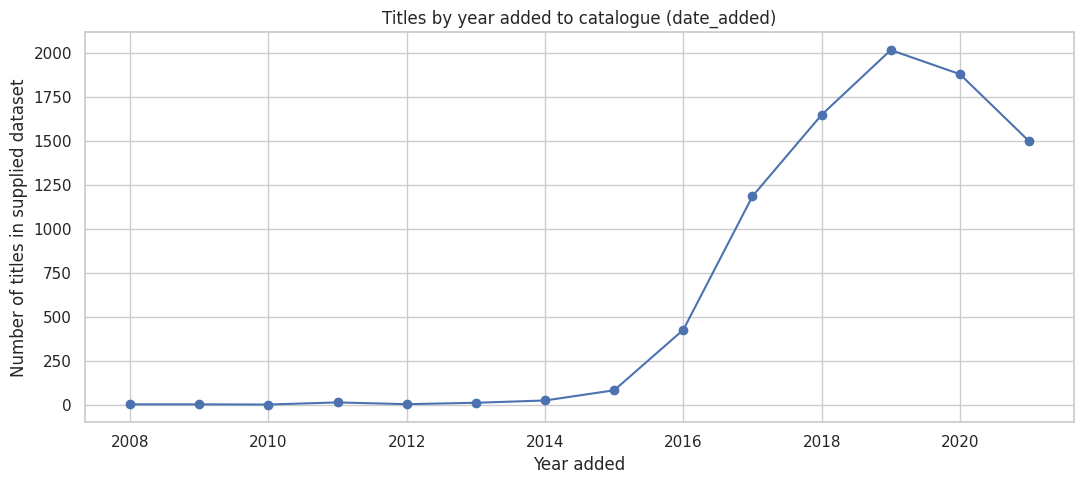

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

trend_source = clean_df.dropna(subset=["date_added"]).copy()
trend_source["date_added_year"] = trend_source["date_added"].dt.year.astype(int)
annual_additions = trend_source.groupby("date_added_year").size().sort_index()
annual_additions = annual_additions.loc[annual_additions.index >= 2008]

display(annual_additions.rename("titles_added").to_frame())
plt.figure(figsize=(11, 5))
plt.plot(annual_additions.index, annual_additions.values, marker="o")
plt.title("Titles by year added to catalogue (date_added)")
plt.xlabel("Year added")
plt.ylabel("Number of titles in supplied dataset")
plt.tight_layout()
plt.show()

,model,MAE,RMSE
0,Linear trend,572.74,657.78
1,Naive (last training year),249.67,265.38


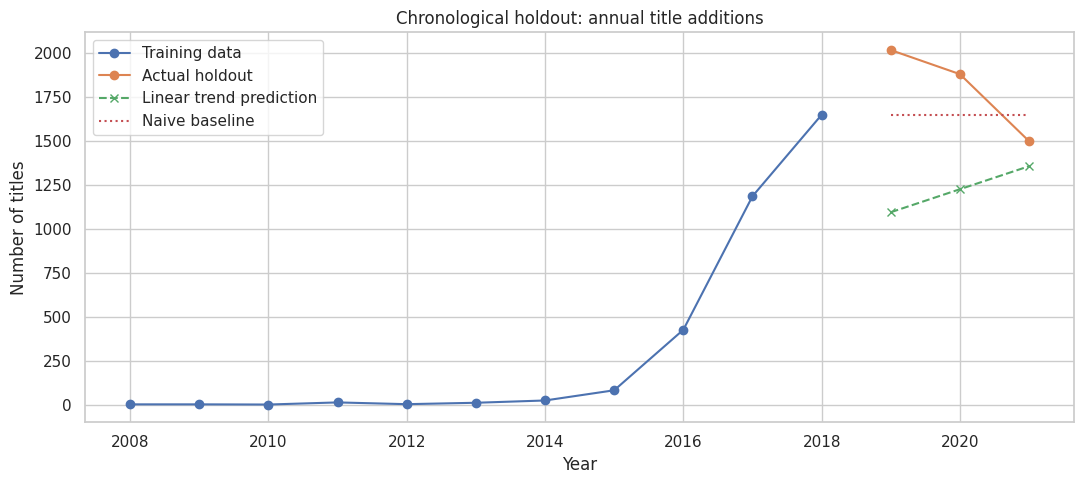

,year,forecast_titles_added
0,2022,1895
1,2023,2064
2,2024,2233


In [11]:
# Chronological train/test split; reserve the last 3 observed years when possible.
series = annual_additions.sort_index()
if len(series) < 6:
    print("Too few annual observations for a meaningful holdout forecast.")
    forecast_results = pd.DataFrame()
else:
    test_size = min(3, max(1, len(series) // 4))
    train = series.iloc[:-test_size]
    test = series.iloc[-test_size:]

    model = LinearRegression()
    X_train = train.index.to_numpy().reshape(-1, 1)
    y_train = train.to_numpy()
    model.fit(X_train, y_train)

    pred_linear = np.maximum(0, model.predict(test.index.to_numpy().reshape(-1, 1)))
    pred_naive = np.repeat(train.iloc[-1], len(test))

    metrics = pd.DataFrame({
        "model": ["Linear trend", "Naive (last training year)"],
        "MAE": [mean_absolute_error(test, pred_linear), mean_absolute_error(test, pred_naive)],
        "RMSE": [mean_squared_error(test, pred_linear) ** 0.5, mean_squared_error(test, pred_naive) ** 0.5],
    })
    display(metrics.round(2))

    plt.figure(figsize=(11, 5))
    plt.plot(train.index, train.values, marker="o", label="Training data")
    plt.plot(test.index, test.values, marker="o", label="Actual holdout")
    plt.plot(test.index, pred_linear, marker="x", linestyle="--", label="Linear trend prediction")
    plt.plot(test.index, pred_naive, linestyle=":", label="Naive baseline")
    plt.title("Chronological holdout: annual title additions")
    plt.xlabel("Year")
    plt.ylabel("Number of titles")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Refit on all available years and project the next three years after the last observed year.
    final_model = LinearRegression().fit(series.index.to_numpy().reshape(-1, 1), series.to_numpy())
    future_years = np.arange(int(series.index.max()) + 1, int(series.index.max()) + 4)
    future_values = np.maximum(0, final_model.predict(future_years.reshape(-1, 1)))
    forecast_results = pd.DataFrame({
        "year": future_years,
        "forecast_titles_added": np.rint(future_values).astype(int)
    })
    display(forecast_results)

## Task 4 interpretation

Use the annual counts, holdout metrics, and plot to decide whether the linear trend performs better than the naive baseline on the held-out years. If it does not, report that honestly. The forecast should be described as an illustrative extrapolation from historical `date_added` counts, not a reliable prediction of future Netflix acquisitions. Structural changes, missing dates, and the dataset's 2021 endpoint limit confidence.

# Task 5 — Machine Learning Classification Model

We will predict the `type` column (`Movie` or `TV Show`) using `rating`, `country`, `listed_in`, and `release_year`. We intentionally exclude `duration`, because values such as “90 min” and “1 Season” can reveal the target almost directly and inflate performance through target leakage.

We compare Logistic Regression and Random Forest using a stratified train/test split. Metrics include accuracy, precision, recall, F1-score, and a confusion matrix.


Logistic Regression — classification report
              precision    recall  f1-score   support

       Movie       1.00      0.99      0.99      1225
     TV Show       0.97      0.99      0.98       533

    accuracy                           0.99      1758
   macro avg       0.98      0.99      0.99      1758
weighted avg       0.99      0.99      0.99      1758



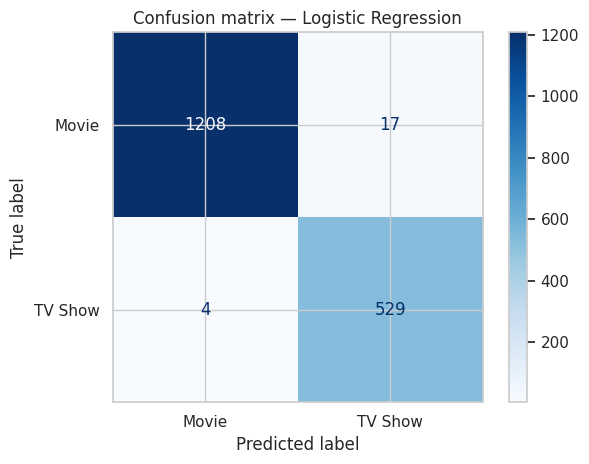


Random Forest — classification report
              precision    recall  f1-score   support

       Movie       0.98      0.95      0.96      1225
     TV Show       0.88      0.96      0.92       533

    accuracy                           0.95      1758
   macro avg       0.93      0.95      0.94      1758
weighted avg       0.95      0.95      0.95      1758



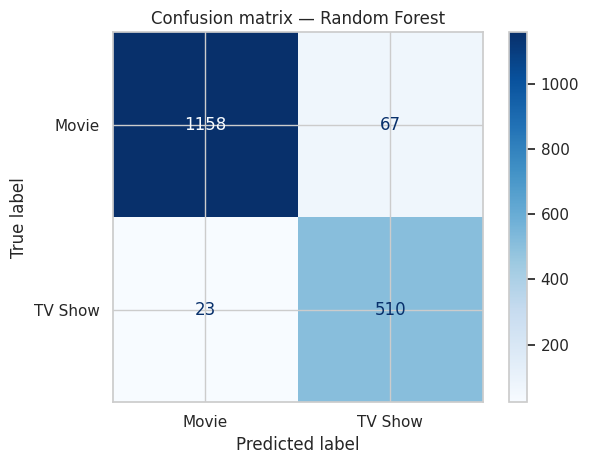

,model,accuracy
0,Logistic Regression,0.988055
1,Random Forest,0.948805


Best model by test accuracy: Logistic Regression


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, ConfusionMatrixDisplay

model_df = clean_df.dropna(subset=["type"]).copy()
# Create text-safe categorical features. Keep multi-valued fields as categorical metadata.
feature_cols = [c for c in ["rating", "country", "listed_in", "release_year"] if c in model_df.columns]
X = model_df[feature_cols].copy()
# Replace Pandas nullable sentinels with NumPy NaN for scikit-learn compatibility.
for col in X.columns:
    if col == "release_year":
        X[col] = pd.to_numeric(X[col], errors="coerce").astype(float)
    else:
        X[col] = X[col].astype(object).where(X[col].notna(), np.nan)
y = model_df["type"].astype(str)

categorical_features = [c for c in feature_cols if c != "release_year"]
numeric_features = [c for c in ["release_year"] if c in feature_cols]

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
transformers = []
if categorical_features:
    transformers.append(("categorical", categorical_pipeline, categorical_features))
if numeric_features:
    transformers.append(("numeric", numeric_pipeline, numeric_features))
preprocessor = ColumnTransformer(transformers=transformers)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(n_estimators=250, min_samples_leaf=2, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
}

results = []
trained_models = {}
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    trained_models[name] = pipeline
    results.append({"model": name, "accuracy": accuracy_score(y_test, predictions)})
    print(f"\n{name} — classification report")
    print(classification_report(y_test, predictions, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap="Blues", values_format="d")
    plt.title(f"Confusion matrix — {name}")
    plt.tight_layout()
    plt.show()

model_comparison = pd.DataFrame(results).sort_values("accuracy", ascending=False)
display(model_comparison)
best_model_name = model_comparison.iloc[0]["model"]
best_model = trained_models[best_model_name]
print("Best model by test accuracy:", best_model_name)

## Task 5 interpretation and responsible evaluation

- Accuracy is the share of correctly classified test records; inspect class-wise precision, recall, and F1 as well.
- Compare the two models on the same held-out test set. A higher score is not automatically proof of real-world usefulness.
- The target is derived from the catalogue's `type` field. This exercise demonstrates a metadata classification workflow, but operational systems should define a practical use case for predicting type before deployment.
- Do not describe the model as predicting user preferences or content success; those labels are not present in this dataset.

# Task 6 — Business Insights Dashboard

This section brings together interactive charts, recommendations, forecast outputs, model metrics, and concise business implications. Plotly charts are interactive inside the notebook. An optional Streamlit app source file is also created so the dashboard can be run locally after installing Streamlit.

In [13]:
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display

# Interactive chart 1: content type
fig_type = px.pie(
    values=clean_df["type"].value_counts().values,
    names=clean_df["type"].value_counts().index,
    title="Catalogue composition by content type",
    hole=0.35
)
fig_type.show()

# Interactive chart 2: top categories
category_counts = clean_df["listed_in"].dropna().str.split(", ").explode().value_counts().head(12).reset_index()
category_counts.columns = ["category", "title_mentions"]
fig_categories = px.bar(category_counts, x="title_mentions", y="category", orientation="h", title="Top listed categories")
fig_categories.update_layout(yaxis={"categoryorder":"total ascending"})
fig_categories.show()

# Interactive chart 3: annual catalogue additions
annual_df = annual_additions.rename_axis("year").reset_index(name="titles_added")
fig_additions = px.line(annual_df, x="year", y="titles_added", markers=True, title="Titles by year added (date_added)")
fig_additions.show()

In [14]:
# Summarize key metrics from the cleaned dataset.
summary = {
    "Total catalogue records": len(clean_df),
    "Movies": int((clean_df["type"] == "Movie").sum()),
    "TV Shows": int((clean_df["type"] == "TV Show").sum()),
    "Missing director": int(clean_df["director"].isna().sum()),
    "Missing country": int(clean_df["country"].isna().sum()),
    "Missing rating": int(clean_df["rating"].isna().sum()),
    "Date-added start": str(clean_df["date_added"].min().date()) if clean_df["date_added"].notna().any() else "Unavailable",
    "Date-added end": str(clean_df["date_added"].max().date()) if clean_df["date_added"].notna().any() else "Unavailable",
    "Classification model selected": best_model_name,
    "Selected model test accuracy": round(float(model_comparison.iloc[0]["accuracy"]), 4),
}
display(pd.DataFrame(summary.items(), columns=["Metric", "Value"]))

,Metric,Value
0,Total catalogue records,8790
1,Movies,6126
2,TV Shows,2664
3,Missing director,2588
4,Missing country,287
5,Missing rating,0
6,Date-added start,2008-01-01
7,Date-added end,2021-09-25
8,Classification model selected,Logistic Regression
9,Selected model test accuracy,0.9881


## Business recommendations

Use the actual outputs from the notebook to tailor these recommendations:

1. **Improve metadata completeness.** Review records missing director or country details, while preserving records when the information cannot be verified.
2. **Support catalogue exploration.** Use the content-based recommender as a prototype for suggesting titles with similar categories and metadata. Validate recommendations with human review and, if available, user feedback.
3. **Use trend charts as descriptive evidence.** Monitor the number of titles added by year and investigate major changes before making acquisition decisions.
4. **Treat forecasts cautiously.** The time series is short and ends in 2021. Compare against simple baselines and refresh the analysis with current, complete data before using forecasts for planning.
5. **Validate classification for a real operational purpose.** The current model is a learning demonstration. Define a business use case, validate errors, and monitor performance before operational deployment.
6. **Add customer and engagement data for stronger conclusions.** Viewing events, user preferences, search activity, and satisfaction signals would be needed to evaluate personalization, engagement, or retention outcomes.

### Overall project conclusion

This project demonstrates an end-to-end data science workflow using Netflix catalogue metadata: data preparation, descriptive analysis, metadata-based recommendations, exploratory forecasting, supervised classification, and dashboard-style communication. Its strongest immediate value is organizing and understanding catalogue information. Claims about audience demand, watch time, retention, or future acquisition success require additional evidence not included in this dataset.

## Optional: Create a Streamlit dashboard file

The following cell writes a separate `app.py` file using the cleaned CSV and interactive Plotly charts. Run it from the folder containing the saved CSV with `streamlit run app.py` after installing `streamlit` and `plotly`. This is optional; the dashboard charts above already work inside the notebook.

In [15]:
streamlit_source = r'''from pathlib import Path
import pandas as pd
import plotly.express as px
import streamlit as st

st.set_page_config(page_title="Netflix Content Intelligence", layout="wide")
st.title("Netflix Content Intelligence Dashboard")
st.caption("Auspify Technologies Data Science Internship — Tasks 1–6")

candidate_paths = [Path("data/processed/netflix_titles_cleaned.csv"), Path("processed/netflix_titles_cleaned.csv"), Path("netflix_titles_cleaned.csv")]
path = next((p for p in candidate_paths if p.exists()), None)
if path is None:
    st.error("Cleaned CSV not found. Run the notebook Task 1 section first, or place netflix_titles_cleaned.csv beside app.py.")
    st.stop()

df = pd.read_csv(path)
if "date_added" in df:
    df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")

c1, c2, c3 = st.columns(3)
c1.metric("Catalogue records", f"{len(df):,}")
c2.metric("Movies", f"{(df['type'] == 'Movie').sum():,}")
c3.metric("TV Shows", f"{(df['type'] == 'TV Show').sum():,}")

st.subheader("Catalogue composition")
type_counts = df["type"].value_counts().rename_axis("type").reset_index(name="count")
st.plotly_chart(px.pie(type_counts, names="type", values="count", hole=0.35), use_container_width=True)

left, right = st.columns(2)
with left:
    if "listed_in" in df:
        cats = df["listed_in"].dropna().str.split(", ").explode().value_counts().head(12).rename_axis("category").reset_index(name="mentions")
        st.plotly_chart(px.bar(cats, x="mentions", y="category", orientation="h", title="Top listed categories"), use_container_width=True)
with right:
    if "date_added" in df:
        additions = df.dropna(subset=["date_added"]).assign(year=lambda x: x["date_added"].dt.year).groupby("year").size().rename("titles_added").reset_index()
        st.plotly_chart(px.line(additions, x="year", y="titles_added", markers=True, title="Titles by year added"), use_container_width=True)

st.subheader("Explore catalogue records")
search = st.text_input("Search title")
filtered = df[df["title"].astype(str).str.contains(search, case=False, na=False)] if search else df
cols = [c for c in ["show_id", "title", "type", "release_year", "rating", "country", "listed_in"] if c in filtered.columns]
st.dataframe(filtered[cols].head(500), use_container_width=True)
st.caption("This dashboard describes catalogue metadata. It does not measure user viewing behaviour or satisfaction.")
'''

app_path = Path("app.py")
app_path.write_text(streamlit_source, encoding="utf-8")
print(f"Created optional Streamlit app source: {app_path.resolve()}")
print("To run it: pip install streamlit plotly && streamlit run app.py")

Created optional Streamlit app source: /mnt/data/app.py
To run it: pip install streamlit plotly && streamlit run app.py


## Submission checklist

- [ ] Submit this `.ipynb` notebook with code cells run and outputs visible.
- [ ] Include the original dataset only if permitted by the internship submission instructions and dataset licensing.
- [ ] Include the cleaned CSV output from Task 1.
- [ ] Include screenshots of EDA charts, recommendations, model evaluation, and dashboard.
- [ ] Include the optional `app.py` and a short demo video if desired.
- [ ] Add your own interpretation of the actual results before submitting; do not report metrics you have not checked.